### MIE370 Project 2 --- Classification and Ensemble models
**Deadline: Oct 25, 21:00 [The deadline is firm and will be enforced strictly. Plan ahead and submit hours before the deadline to avoid the risk of lateness penalty.]**

**Academic Integrity**

This project is individual - it is to be completed on your own. If you have questions, please post your query in the MIE370 Piazza Q&A forums (the answer might be useful to others!).

Do not share your code with others, or post your work online. Do not submit code that you have not written yourself. Students suspected of plagiarism on projects or assessments will be referred to the department for formal discipline for breaches of the Student Code of Conduct.

Please fill out the following:

Full Name: Rowan Nepulangoda  

Student ID: 1010864904

UTorID: nepulang

**Three submission files are required:**

For submitting this project, three files must be submitted on Quercus by the project deadline:

1) The complete Jupyter file (in .ipynb format) (that completely compiles on Google colab without any errors regardless of the computer used.)

2) A self-contained and complete HTML printout of the same Jupyter file with all the output printed as well as all the code, text cells, comments, and figures.

3) Appendix pdf file of all prompts and all responses for all interactions you have had regarding this project with any AI assistant tool (Chat GPT etc.). If you do not use any AI assistant tool at all, this appendix pdf file is not needed.

**Policy regarding the use of AI assistant tools**

If you use a generative AI tool (e.g., ChatGPT, GitHub Copilot, or any other similar tool) to get ideas and/or partial answers for projects or assignments or to generate any code and/or text, you must declare in your submission the tools that you have used and describe the usage, and include in your submission an appendix that captures all the interactions (prompts and responses).

You will not be penalized for the declared use of such AI assistant tools, and the grading decisions will be based on your original contributions as well as the efforts that you make to check and/or correct the answers provided by the tool. Students are ultimately accountable for the work they submit. Failure to fully declare the use of this tool will be considered "unauthorized assistance" and will have consequences (See B.I. of the [U of T CODE OF BEHAVIOUR ON ACADEMIC MATTERS](https://governingcouncil.utoronto.ca/secretariat/policies/code-behaviour-academic-matters-july-1-2019))

## **Marking Scheme:**

This project is worth **9 percent** of your final grade.

Draw a plot or table where necessary to summarize your findings.

**Practice Vectorized coding**: If you need to write a loop in your solution, think about how you can implement the same functionality with vectorized operations. Try to avoid loops as much as possible (in some cases, loops are inevitable).




### How to obtain an **HTML** file from an **IPYNB** file

1. Download the IPYNB file of your complete project: `File -> Download .ipynb`

2. Click on the Files icon on the far left menu of a new Colab session

3. Select & upload your `.ipynb` file you just downloaded, and then copy its path (right click) (you might need to hit the Refresh button before your file shows up)


4. Replace XXXX with the copied path and then execute the following in a Colab cell:
```
%%shell
jupyter nbconvert --to html XXXX
```

5. An HTML version of your notebook will appear in the Colab session files and you can download it.

6. Submit **both** <font color='red'>`HTML` and `IPYNB`</font>  files on Quercus (before the deadline) for grading.



More info on converting IPYNB to HTML: https://stackoverflow.com/a/64487858



## Working in VS Code

Install the required packages if needed:

```bash
python3 -m pip install numpy pandas scipy matplotlib seaborn scikit-learn ipykernel nbconvert
```

Open the notebook, select the correct Python kernel, and run the setup cell before starting the assignment.

# Assignment Roadmap

| Part | Main topic | Marks |
|---|---|---:|
| Part 0 | Getting started: identify the target and the number of features | 2 |
| Part A | Pre-processing: encoding, X/y preparation, downsampling, train/test split, standardization | 13 |
| Part B | KNN: sweeping `k` with cross-validation, overfitting vs. underfitting | 20 |
| Part C | Tree-based models (DT, RF, gradient boosting) and hyperplane-based models (logistic regression, polynomial and RBF SVMs) with hyperparameter tuning, plus a CV summary table | 35 |
| Part D | Feature importance: permutation importance for every tuned model, comparing models, re-training on the important features | 20 |
| Part E | Test-set evaluation: performance metrics, confusion table, ROC and AUC | 10 |
| **Total** | | **100** |
| Bonus | Tune and evaluate up to 2 extra models (SGT, EBM, XGBoost, FIGS) | +10 |

Required total: **100 marks**. The optional question is worth up to **10 additional bonus marks**.


### Setup

Run the next code cell before Part 0. It imports the required libraries. 

In [82]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint, expon

from sklearn.model_selection import train_test_split, cross_validate, RandomizedSearchCV, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)

# Project 2 **[100 Marks]**
You are going to apply several ML methods for a predictive task on a new dataset.

We're going to work with the [MAGIC Gamma Telescope dataset](https://www.openml.org/d/43971). When a high-energy particle hits the atmosphere, it creates a shower of secondary particles that emits a faint flash of light. A ground-based telescope camera records this flash as an image, which is summarized by fitting an ellipse to it. The task is to classify each shower as either a **gamma ray** (`g`, the signal astronomers are interested in) or a **hadron** (`h`, background cosmic rays), using the shape of that ellipse.


In [83]:
from sklearn.datasets import fetch_openml

df = fetch_openml(data_id=43971, as_frame=True).frame
df.columns = df.columns.str.rstrip(':')  # OpenML column names end with ':'

## Part 0: Getting started **[2 Marks]**

* Identify the target column (the variable we aim to predict)? class **[1]**
* How many features do we have in this dataset in order to predict the target? 11 **[1]**

In [84]:
df.head()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,69.2979,26.8809,3.1930,0.2065,0.1074,39.6296,44.3457,-23.0604,9.3234,248.750,g
1,24.5939,10.1418,2.5676,0.5007,0.2693,-8.4503,15.2452,-7.0283,17.0056,173.288,g
2,55.4800,27.1606,3.1826,0.2299,0.1225,43.1016,54.2556,13.7406,32.2220,262.181,g
3,12.6594,11.7413,2.1351,0.7033,0.3846,-15.8596,9.4522,-8.7126,43.5434,227.711,g
4,38.6204,20.5632,2.9770,0.2478,0.1270,-13.8229,-31.3983,-13.1337,5.8671,192.467,g


Based on the table, the target column we aim to predict is the class and there are 11 features to this dataset. 

# Part A: Pre-processing **[13 Marks Total]**

## Part A1: Encoding the Target **[2 Marks]**

Each row in this dataset represents a single particle shower recorded by the telescope.

The columns describe the shape of the ellipse fitted to the shower image, such as its length, width, brightness, and orientation. The `class` column indicates whether the shower was caused by a gamma ray or a hadron.

Convert the `class` column so that it contains 1 (if the shower is a gamma ray, `g`) or 0 (if it is a hadron, `h`). This will be the target value to classify the data. **[2]**

In [85]:
### YOUR CODE HERE ###

df["class"] = (df["class"] == "g").astype(int)
df.head()

,fLength,fWidth,fSize,fConc,fConc1,fAsym,fM3Long,fM3Trans,fAlpha,fDist,class
0,69.2979,26.8809,3.1930,0.2065,0.1074,39.6296,44.3457,-23.0604,9.3234,248.750,1
1,24.5939,10.1418,2.5676,0.5007,0.2693,-8.4503,15.2452,-7.0283,17.0056,173.288,1
2,55.4800,27.1606,3.1826,0.2299,0.1225,43.1016,54.2556,13.7406,32.2220,262.181,1
3,12.6594,11.7413,2.1351,0.7033,0.3846,-15.8596,9.4522,-8.7126,43.5434,227.711,1
4,38.6204,20.5632,2.9770,0.2478,0.1270,-13.8229,-31.3983,-13.1337,5.8671,192.467,1


## Part A2: Preparing X and y **[2 Marks]**

The first argument of [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html) is the **X value** (the quantities we use in order to predict), and the second argument is the **y value** (the quantity we want to predict).

Prepare the variables `X` (all columns except `class`) and `y` (the `class` column). **[2]**

Check [this](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.drop.html) example to see how to drop columns.

*hint: use axis = 1 to drop columns, otherwise it's defaulted to axis = 0 which is used to drop rows*

In [86]:
### YOUR CODE HERE ###

# We want to predict the class column

target = 'class' 

# Drops every columns except for the target column
X = df.drop(target, axis=1) 
Y = df[target]                

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (13376, 10)
Y shape: (13376,)


## Part A3: Downsampling **[3 Marks]**

Several models in Part C are tuned with hundreds of cross-validated fits, which would take a long time on all 13,376 showers. Downsample `X` and `y` to 3,000 samples via **stratified sampling with `random_state=24`**. Make sure the rows of `X` and `y` still line up after downsampling. **[2]**

Print the shape of `X` and the number of samples in each class after downsampling. **[1]**

*HINT: [consider how sklearn's `train_test_split` function might be able to help do this](https://www.geeksforgeeks.org/machine-learning/how-to-implement-stratified-sampling-with-scikit-learn/)*

In [87]:
### YOUR CODE HERE ###


n_samples = 3000            
RANDOM_STATE = 24       

# Uses a train test split to and keeps train size at 30
X_small, _, y_small, _ = train_test_split(
    X, Y,
    train_size=n_samples,
    stratify=Y,
    random_state=RANDOM_STATE,
)

print("X shape:", X_small.shape)
print("Samples per class:")
print(y_small.value_counts())



X shape: (3000, 10)
Samples per class:
class
1    1500
0    1500
Name: count, dtype: int64


## Part A4: Data Splitting **[2 Marks]**

**Split the downsampled dataset** into a train and a test set **"80:20"**, **stratified based on `class`** (`stratify=y`), and use **``random_state=24``**. The test set is set aside (untouched) for final evaluation, once hyperparameter optimization is complete. **[2]**

In [88]:
### YOUR CODE HERE ###

# Takes the downsampled data and turns it into an 80:20 split

X_small_train, X_small_test, y_small_train, y_small_test = train_test_split(
    X_small, y_small,         
    test_size=0.2,       
    stratify=y_small,        
    random_state=RANDOM_STATE,
)

print("Train:", X_small_train.shape, "Test:", X_small_test.shape)
print(y_small_train.value_counts(normalize=True))
print(y_small_test.value_counts(normalize=True))

Train: (2400, 10) Test: (600, 10)
class
1    0.5
0    0.5
Name: proportion, dtype: float64
class
1    0.5
0    0.5
Name: proportion, dtype: float64


## Part A5: Standardization **[4 Marks]**

Standardize the training and test data ([Help](https://scikit-learn.org/stable/modules/preprocessing.html)). **[2]**

Use `seaborn.lmplot` ([help here](https://seaborn.pydata.org/generated/seaborn.lmplot.html)) to draw a plot of the training set where the x-axis is `fAlpha`, the y-axis is `fLength`, and the color of each datapoint indicates its class. Then draw the same plot using the standardized features. What's different? **Why do they look similar?** Based on your observation, what is the advantage of standardization? **[2]**

**Note:** When we standardize a dataset, it matters if the data points are in our training set or test set. The training set is available for us to train a model - we can use it however we want. The test set, however, represents a subset of data that is not available for us during training. For example, the test set can represent the data that someone who bought our model would use to see how the model performs (which they are not willing to share with us).
Therefore, we cannot use the mean or standard deviation of the whole dataset to standardize it - we can only use the mean and standard deviation of the training set. When the model is ready for testing, we provide our scalers (mean and standard deviation of our training set) to the person who is going to test the model. They can scale their data (test set) with our training set's mean and standard deviation. It is unlikely that the scaled test set would exactly have a mean of zero and a standard deviation of one, but there is no such requirement for the model to perform well.

**To summarize: We fit the StandardScaler only on the training set. We transform both training and test sets with that scaler.**

**Use the standardized data for all remaining parts of this project.**

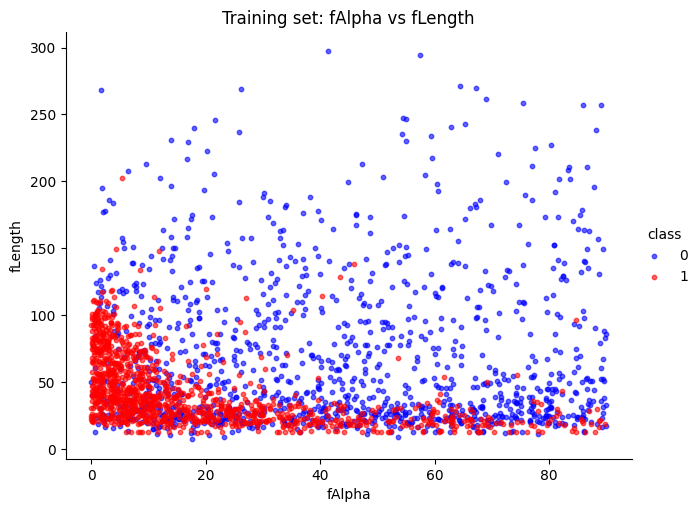

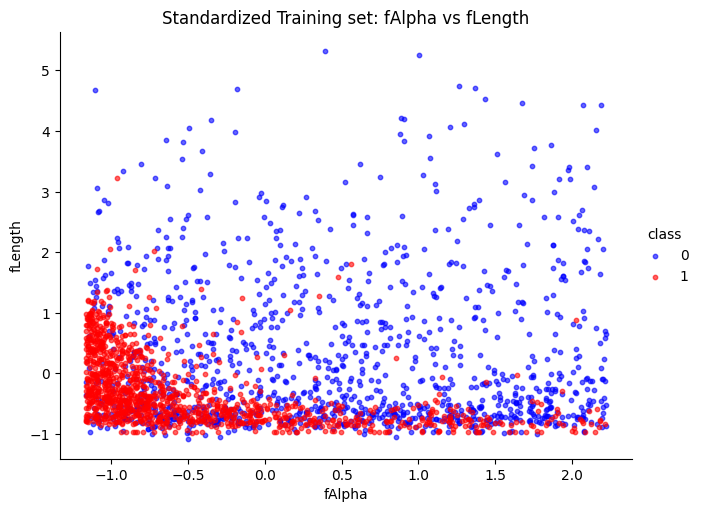

In [89]:
### YOUR CODE HERE ###

# Plotting the downsized training data

def plot_alpha_vs_length(X_data, y_data, title):
    # Combine features and labels so seaborn can colour by class
    plot_df = X_data.copy()
    plot_df["class"] = y_data.values

    sns.lmplot(
        data=plot_df,
        x="fAlpha",
        y="fLength",
        hue="class",
        palette={1: "red", 0: "blue"},   # 1 = gamma, 0 = hadron
        fit_reg=False,                   # points only; set True for trend lines
        scatter_kws={"s": 10, "alpha": 0.6},
        height=5,
        aspect=1.3,
    )
    plt.title(title)
    plt.show()

plot_alpha_vs_length(X_small_train, y_small_train, "Training set: fAlpha vs fLength")

scaler = StandardScaler()

# Fit on the training set only, then apply the same scaling to both sets
X_small_train_scaled = scaler.fit_transform(X_small_train)
X_small_test_scaled = scaler.transform(X_small_test)

# Restore column names and index (StandardScaler returns NumPy arrays)
X_small_train_scaled = pd.DataFrame(X_small_train_scaled, columns=X_small_train.columns, index=X_small_train.index)
X_small_test_scaled = pd.DataFrame(X_small_test_scaled, columns=X_small_test.columns, index=X_small_test.index)

plot_alpha_vs_length(X_small_train_scaled, y_small_train, "Standardized Training set: fAlpha vs fLength")

**A5 Response**

The shape looks similar due to standardization preserving the distribution of the data. Based on the observation of the standardized plot, it is evident that the magnitude of the scale of both flength and falpha have decreased significantly. This is one of the strengths of standardization as it prevents certain columns from having too much influence on the data by simply having a very large magnitude. By instead focussing on how many standard deviations we are away from the mean, we are able to get rid of this issue. 

# Part B: KNN **[20 Marks Total]**

## Part B1: Sweeping `k` **[8 Marks]**

Let's create a KNN Model to predict whether a shower was caused by a gamma ray from the shape of its image!

Using 5-fold cross-validation on the standardized training set, sweep `k` (number of neighbors) from 1 to 90. For each `k`, record both the **mean training accuracy** and the **mean validation accuracy** across the folds. Show both curves on a single plot of accuracy vs `k`. **[8]**

cv=5: mean train acc = 0.8464, mean val acc = 0.7850
    train_acc   val_acc
k                      
1    1.000000  0.760000
2    0.903646  0.747500
3    0.874583  0.783750
4    0.861354  0.777500
5    0.846354  0.785000
..        ...       ...
85   0.772812  0.763750
86   0.773125  0.765000
87   0.770521  0.763333
88   0.772188  0.764167
89   0.769896  0.763750

[89 rows x 2 columns]


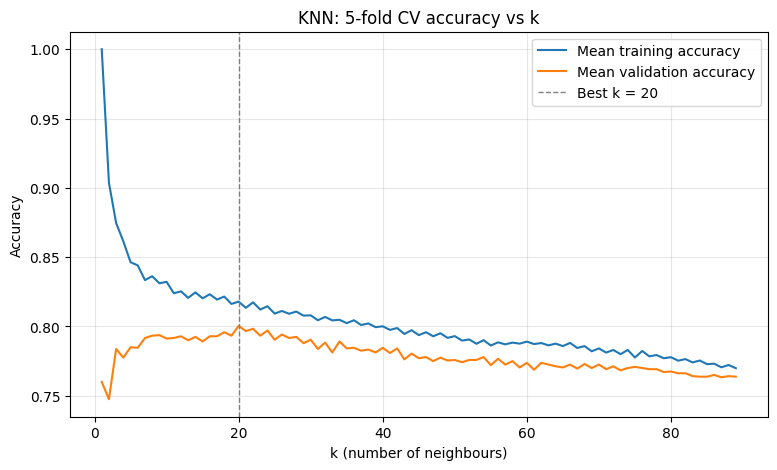

In [90]:
### YOUR CODE HERE ###

def knn_cv_scores(k, X, y, folds=5):
    """Return mean training and validation accuracy for a KNN with k neighbours."""
    cv_results = cross_validate(
        KNeighborsClassifier(n_neighbors=k),
        X, y,
        cv=folds,
        scoring="accuracy",
        return_train_score=True,  
    )
    return cv_results["train_score"].mean(), cv_results["test_score"].mean()

# Single model
cv = 5 
train_acc, val_acc = knn_cv_scores(cv, X_small_train_scaled, y_small_train)
print(f"cv={cv}: mean train acc = {train_acc:.4f}, mean val acc = {val_acc:.4f}")

# Optional: record results across several k values
k_values = range(1, 90)   
scores = [knn_cv_scores(k, X_small_train_scaled, y_small_train) for k in k_values]
results = pd.DataFrame(scores, index=k_values, columns=["train_acc", "val_acc"])
results.index.name = "k"
print(results)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(results.index, results["train_acc"], label="Mean training accuracy")
ax.plot(results.index, results["val_acc"], label="Mean validation accuracy")

# Mark the k with the highest validation accuracy
best_k = results["val_acc"].idxmax()
ax.axvline(best_k, color="grey", linestyle="--", linewidth=1,
           label=f"Best k = {best_k}")

ax.set_xlabel("k (number of neighbours)")
ax.set_ylabel("Accuracy")
ax.set_title("KNN: 5-fold CV accuracy vs k")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Part B2: Best `k` **[4 Marks]**

What is the best `k`? What is the highest mean cross-validation accuracy? **[2]**

Pick the best `k` and refit a KNN model with it on the full standardized training set. This refit model is the KNN model you will use in Parts C3, D and E. **[2]**

In [91]:
### YOUR CODE HERE ###

# Assume full standardized training sets means traning set without k fold CV 

best_k = results["val_acc"].idxmax()
print(f"Best k based on validation accuracy: {best_k}")

knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_small_train_scaled, y_small_train)

print(f"Refit KNN with k={best_k} on {X_small_train_scaled.shape[0]} training samples")

Best k based on validation accuracy: 20
Refit KNN with k=20 on 2400 training samples


## Part B3: Overfitting vs. Underfitting **[8 Marks]**

Using the training and validation curves from Part B1:

* Which range of `k` leads to overfitted models, and which range leads to underfitted models? Justify your answer using the gap between the two curves. **[4]**
* Why is the training accuracy exactly 1.0 at `k = 1`? Explain in terms of how KNN makes predictions, and why this does not mean `k = 1` is a good model. **[4]**

*Your answer here*

The best range of overfitting would be between k=1 and k=10. We can see examples of overfitting where there is a very training accuracy but a very low validation accuracy. Additionally, we can also see examples of underfitting within the range of k=80 and k=90 where the model is unable to adequately recognize key patterns in the data and has a poor mean training accuracy and mean validation accuracy compared to smaller ranges of k. 

# Part C: Other Built-in Models & Hyperparameter Tuning **[35 Marks Total]**

In this part, you will use some built-in models, and **tune their hyperparameters** to achieve high accuracy/scores. Use the standardized training set with all features.

The models you will be using are:

1. Decision Tree (Part C1.1)
2. Random Forest (Part C1.2)
3. Gradient Boosted Trees (Part C1.3)
4. Logistic Regression (Part C2.1)
5. SVM with Polynomial Kernel (Part C2.2)
6. SVM with RBF Kernel (Part C2.3)

(5 marks per model)

For every model that has a `random_state` parameter, set `random_state=24` (e.g. `DecisionTreeClassifier(random_state=24)`) so your results are reproducible.

Keep the best tuned version of each model (e.g. `best_estimator_` from the search), since you will need them in Parts D and E.

## Part C-1: Tree-based Models **[15 Marks Total]**

## Part C1.1: Decision Tree Classifier **[5 Marks]**

Train a decision tree classifier on the standardized dataset (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) and check the example there.) Tune the hyperparameters `max_depth` and `min_samples_split` using [RandomizedSearchCV ](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) with n_iter=250, you should set the ranges of the hyperparameters as the following:

* `'max_depth': randint(1, 10)`
* `'min_samples_split': randint(2, 50)`


For RandomizedSearchCV, use:

* `cv=5`,
* `verbose=2`,
* `random_state=24`,
* `n_jobs=-1`,
* `return_train_score=True`

Record & print out:

* the highest mean cross-validated accuracy/score, and
* the value(s) of the hyperparameter(s) you tuned that achieved the highest accuracy/score.
* i.e: *Best performance using decision tree is 0.987654321 with a max depth of 8 and a min samples split of 25*


In [92]:
### YOUR CODE HERE ###

# Assume we are using the downsized and scaled training data from Part A


RANDOM_STATE = 24   # placeholder: set your seed here
N_ITER = 250         # placeholder: number of random combinations to try

# Placeholder: fill in hyperparameter names and ranges, e.g. "name": randint(low, high)
param_dist = {
     "max_depth": randint(1, 10),
     "min_samples_split": randint(2, 50),
}

dt_search = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=N_ITER,
    cv=5,
    scoring="accuracy",
    verbose=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True,
)
dt_search.fit(X_small_train_scaled, y_small_train)

dt_best = dt_search.best_estimator_   # already refit on the full training set

print(f"Best mean CV accuracy: {dt_search.best_score_:.4f}")
print("Best hyperparameters:", dt_search.best_params_)


Fitting 5 folds for each of 250 candidates, totalling 1250 fits
Best mean CV accuracy: 0.7975
Best hyperparameters: {'max_depth': 5, 'min_samples_split': 49}


## Part C1.2: Random Forests **[5 Marks]**

Train a Random Forest classifier on the standardized full feature dataset (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) and check the example there.) Tune the `n_estimators` and `max_features` parameters of the classifier using [RandomizedSearchCV ](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) with n_iter=250, using the following hyperparameter ranges:

* `max_features : ['sqrt', 'log2', 0.1, 0.25, 0.5]`,
* `n_estimators : randint(10, 200)`


For RandomizedSearchCV, use:

* `cv=5`,
* `verbose=2`,
* `random_state=24`,
* `n_jobs=-1`,
* `return_train_score=True`

Record & print out:

* the highest mean cross-validated accuracy/score, and
* the value(s) of the hyperparameter(s) you tuned that achieved the highest accuracy/score.
* i.e: *Best n_estimators: 60, Best Max Features: log2, Best Accuracy: 0.987654321*


In [93]:
### YOUR CODE HERE ###

# Assume we are using the downsized and scaled training data from Part A

RANDOM_STATE = 24   # placeholder: set your seed here
N_ITER = 250         # placeholder: number of random combinations to try

# Placeholder: fill in hyperparameter names and ranges
# Lists and scipy distributions can be mixed, e.g. "name": [a, b, c] or "name": randint(low, high)
param_dist = {
    "max_features": ["sqrt", "log2", 0.1, 0.25, 0.5],
    "n_estimators": randint(10, 200),
}

rf_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=N_ITER,
    cv=5,
    verbose=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True,
)
rf_search.fit(X_small_train_scaled, y_small_train)

rf_best = rf_search.best_estimator_  

print(f"Best mean CV accuracy: {rf_search.best_score_:.4f}")
print("Best hyperparameters:", rf_search.best_params_)

Fitting 5 folds for each of 250 candidates, totalling 1250 fits
Best mean CV accuracy: 0.8375
Best hyperparameters: {'max_features': 0.1, 'n_estimators': 101}


## Part C1.3: Gradient Boosting Classifier **[5 Marks]**

Similarly, train a Gradient Boosting classifier on the standardized full feature dataset (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html) and check the example there.)


Then tune the hyperparameters `n_estimators`, `learning_rate`, and `max_depth` using [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

For the ranges of those hyperparameters please do the following:  

*   `learning_rate = [0.007, 0.053, 0.082, 0.099, 0.130]`
*   `max_depth = [1,2,3] `
*   `n_estimators = [1, 10, 50, 100, 300, 500]`


For GridSearchCV, use:

* `cv=5`,
* `verbose=2`,
* `n_jobs=-1`,
* `return_train_score=True`

Record & print out:

* the highest mean cross-validated accuracy/score, and
* the value(s) of the hyperparameter(s) you tuned that achieved the highest accuracy/score.
* i.e: *n_estimators: 100, Best Learning Rate: 0.053, Best Max Depth: 2, Best Accuracy: 0.987654321*

In [94]:
### YOUR CODE HERE ###

# Assume we are using the downsized and scaled training data from Part A

RANDOM_STATE = 24   # placeholder: set your seed here

param_grid = {
    "max_depth": [1,2,3],
    "learning_rate": [0.007, 0.053, 0.082, 0.099, 0.130],
    "n_estimators": [1, 10, 50, 100, 300, 500]
}

gb_search = GridSearchCV(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    verbose=2,
    n_jobs=-1,
    return_train_score=True,
)
gb_search.fit(X_small_train_scaled, y_small_train)

gb_best = gb_search.best_estimator_

print(f"Best mean CV accuracy: {gb_search.best_score_:.4f}")
print("Best hyperparameters:", gb_search.best_params_)

Fitting 5 folds for each of 90 candidates, totalling 450 fits
Best mean CV accuracy: 0.8363
Best hyperparameters: {'learning_rate': 0.082, 'max_depth': 2, 'n_estimators': 300}


## Part C-2: Hyperplane-based Models **[15 Marks Total]**

## Part C2.1: Logistic Regression **[5 Marks]**

Train a logistic regression classifier on the standardized full feature dataset (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) and check the example there.) Set `max_iter=1000` so the solver has enough iterations to converge.

Then tune the regularization parameter `C` using [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html). Smaller values of `C` mean stronger regularization.

set:

* `'C': np.logspace(-3, 3, 13)`

For GridSearchCV, use:

* `cv=5`,
* `verbose=2`,
* `n_jobs=-1`,
* `return_train_score=True`

Record & print out:

* the highest mean cross-validated accuracy/score, and
* the value(s) of the hyperparameter(s) you tuned that achieved the highest accuracy/score.
* i.e: *Best C: 0.1, Best Accuracy: 0.987654321*

In [95]:
### YOUR CODE HERE ###

# Assume we are using the downsized and scaled training data from Part A

MAX_ITER = 1000   # placeholder: solver iteration limit

# Placeholder: fill in hyperparameter names and lists of values to try
param_grid = {
    "C":np.logspace(-3, 3, 13),  
}

lr_search = GridSearchCV(
    LogisticRegression(max_iter=MAX_ITER),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    verbose=2,
    n_jobs=-1,
    return_train_score=True,
)
lr_search.fit(X_small_train_scaled, y_small_train)

lr_best = lr_search.best_estimator_

print(f"Best mean CV accuracy: {lr_search.best_score_:.4f}")
print("Best hyperparameters:", lr_search.best_params_)

Fitting 5 folds for each of 13 candidates, totalling 65 fits
Best mean CV accuracy: 0.7671
Best hyperparameters: {'C': np.float64(0.01)}


## Part C2.2: SVM with Polynomial Kernel  **[5 Marks]**

Train an SVM with Polynomial Kernel on the standardized full feature dataset (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) and check the example there.) with `poly` as the kernel setting. Tune the `C` and `degree` parameters of the classifier using [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) with `n_iter = 250`.

set:
* ` 'C': expon(scale=10)`
* `'degree': randint(2, 6)`
    
For RandomizedSearchCV, use:

* `cv=5`,
* `verbose=2`,
* `random_state=24`,
* `n_jobs=-1`,
* `return_train_score=True`

Record & print out:

* the highest mean cross-validated accuracy/score, and
* the value(s) of the hyperparameter(s) you tuned that achieved the highest accuracy/score.
* i.e: *Best C: 2, Best degree: 5, Best Accuracy: 0.98754321*

In [ ]:
### YOUR CODE HERE ###

# Assume we are using the downsized and scaled training data from Part A

RANDOM_STATE = 24   # placeholder: set your seed here
N_ITER = 250         # placeholder: number of random combinations to try

# Placeholder: fill in hyperparameter names and distributions
param_dist = {
    "C": expon(scale=10),
    "degree": randint(2, 6),
}

svm_poly_search = RandomizedSearchCV(
    SVC(kernel="poly", random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=N_ITER,
    cv=5,
    scoring="accuracy",
    verbose=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True,
)
svm_poly_search.fit(X_small_train_scaled, y_small_train)

svm_poly_best = svm_poly_search.best_estimator_

print(f"Best mean CV accuracy: {svm_poly_search.best_score_:.4f}")
print("Best hyperparameters:", svm_poly_search.best_params_)

Fitting 5 folds for each of 250 candidates, totalling 1250 fits


## Part C2.3: SVM with Radial Kernel **[5 Marks]**

Similarly train an SVM with radial kernel on the standardized full feature dataset (read the [documentation](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) and check the example there.) with `rbf` as the kernel value. Tune the `C` and `gamma` parameters of the classifier using [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html) with `n_iter = 250`.

set:

*  `'C': expon(scale=10)`
* `'gamma': [0.01, 0.1, 1, 10]`

For RandomizedSearchCV, use:

* `cv=5`,
* `verbose=2`,
* `random_state=24`,
* `n_jobs=-1`,
* `return_train_score=True`

Record & print out:

* the highest mean cross-validated accuracy/score, and
* the value(s) of the hyperparameter(s) you tuned that achieved the highest accuracy/score.
* i.e: *Best C: 2, Best Gamma: 0.1, Best Accuracy: 0.98754321*

In [ ]:
### YOUR CODE HERE ###

# Assume we are using the downsized and scaled training data from Part A

RANDOM_STATE = 24   # placeholder: set your seed here
N_ITER = 250         # placeholder: number of random combinations to try

# Placeholder: fill in hyperparameter names and distributions or lists
param_dist = {
    "C": expon(scale=10),
    "gamma": [0.01, 0.1, 1, 10]
}

svm_rbf_search = RandomizedSearchCV(
    SVC(kernel="rbf", random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=N_ITER,
    cv=5,
    scoring="accuracy",
    verbose=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True,
)
svm_rbf_search.fit(X_small_train_scaled, y_small_train)

svm_rbf_best = svm_rbf_search.best_estimator_

print(f"Best mean CV accuracy: {svm_rbf_search.best_score_:.4f}")
print("Best hyperparameters:", svm_rbf_search.best_params_)

Fitting 5 folds for each of 250 candidates, totalling 1250 fits
Best mean CV accuracy: 0.8346
Best hyperparameters: {'C': np.float64(12.168248098503692), 'gamma': 0.1}


## Part C3: Cross-Validation Summary **[5 Marks]**

So far you have developed 7 models: the tuned KNN from Part B and the 6 models above.

Make a table of the best mean cross-validation accuracy and the best hyperparameters for all 7 models.

In [ ]:
### YOUR CODE HERE ###

def format_params(params):
    """Turn a parameter dict into a readable string, rounding floats."""
    return ", ".join(
        f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}"
        for k, v in params.items()
    )

# KNN was tuned manually, so its entry is built from the sweep results
rows = [
    {"Model": "KNN",
     "Mean CV Accuracy": results["val_acc"].max(),
     "Best Hyperparameters": f"n_neighbors={results['val_acc'].idxmax()}"},
]

# Models tuned with a search object: (display name, fitted search)
searches = [
    ("Decision Tree",       dt_search),
    ("Random Forest",       rf_search),
    ("Gradient Boosting",   gb_search),
    ("Logistic Regression", lr_search),
    ("SVM (Polynomial)",    svm_poly_search),
    ("SVM (RBF)",           svm_rbf_search),
]

rows += [
    {"Model": name,
     "Mean CV Accuracy": search.best_score_,
     "Best Hyperparameters": format_params(search.best_params_)}
    for name, search in searches
]

summary = (pd.DataFrame(rows)
             .sort_values("Mean CV Accuracy", ascending=False)
             .reset_index(drop=True))

pd.set_option("display.max_colwidth", None)   # avoid truncating parameter strings
summary.round({"Mean CV Accuracy": 4})

,Model,Mean CV Accuracy,Best Hyperparameters
0,Random Forest,0.8375,"max_features=0.1, n_estimators=101"
1,Gradient Boosting,0.8362,"learning_rate=0.082, max_depth=2, n_estimators=300"
2,SVM (RBF),0.8346,"C=12.17, gamma=0.1"
3,SVM (Polynomial),0.8092,"C=37.67, degree=3"
4,KNN,0.8004,n_neighbors=20
5,Decision Tree,0.7975,"max_depth=5, min_samples_split=49"
6,Logistic Regression,0.7671,C=0.01


# Part D: Feature Importance **[20 Marks Total]**

Different models can rely on very different features to make their predictions. In this part, you will measure how much each tuned model depends on each feature using [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).

**How permutation importance works.** Start with a fitted model and a dataset, and record the model's accuracy on that data (the *baseline*). Then, for one feature at a time:

1. Randomly shuffle the values in that feature's column, leaving every other column (and the labels) unchanged.
2. Re-compute the model's accuracy on the shuffled data. The model is **not** re-trained.
3. The importance of the feature is the drop in accuracy: `baseline accuracy - shuffled accuracy`.

Shuffling keeps the feature's overall distribution the same but breaks its relationship with the target, so the model can no longer use it. If accuracy drops a lot, the model relies heavily on that feature. If accuracy barely changes (importance near 0), the model is not using it. Because shuffling is random, the process is repeated several times (`n_repeats`) and the drops are averaged.

A few things to keep in mind:

* It works for **any** model, since it only needs the model's predictions. This lets us compare KNN, trees, and SVMs on the same scale.
* It measures what a **specific fitted model** relies on, not how useful a feature is in general. Two models can give very different importances on the same data.
* When two features are strongly correlated (e.g. `fConc` and `fConc1`), shuffling one of them may hurt little, since the model can still get the same information from the other. Both can then look less important than they really are.

## Part D1: Permutation Importance **[8 Marks]**

For each of the 7 best models from Part C3, compute the permutation importance of every feature using [`permutation_importance`](https://scikit-learn.org/stable/modules/generated/sklearn.inspection.permutation_importance.html) on the standardized **training** set, with `n_repeats=10` and `random_state=24`. Store the mean importances of all models in a single DataFrame (rows = features, columns = models). **[8]**

*Do not use the test set here - it stays untouched until Part E.*

In [ ]:
### YOUR CODE HERE ###

N_REPEATS = 10         
RANDOM_STATE = 24    

models = {
    "KNN":                 knn_best,
    "Decision Tree":       dt_best,
    "Random Forest":       rf_best,
    "Gradient Boosting":   gb_best,
    "Logistic Regression": lr_best,
    "SVM (Polynomial)":    svm_poly_best,
    "SVM (RBF)":           svm_rbf_best,
}

def mean_importance(model, X, y):
    """Mean drop in accuracy when each feature is shuffled."""
    result = permutation_importance(
        model, X, y,
        n_repeats=N_REPEATS,
        random_state=RANDOM_STATE,
        scoring="accuracy",
        n_jobs=-1,
    )
    return result.importances_mean


importance_df = pd.DataFrame(
    {name: mean_importance(model, X_small_train_scaled, y_small_train)
     for name, model in models.items()},
    index=X_small_train_scaled.columns,
)

importance_df.round(4)

,KNN,Decision Tree,Random Forest,Gradient Boosting,Logistic Regression,SVM (Polynomial),SVM (RBF)
fLength,0.0324,0.1076,0.0565,0.0818,0.0644,0.1397,0.1151
fWidth,0.0233,0.0392,0.0705,0.0861,0.0094,0.0871,0.0633
fSize,0.0583,0.0677,0.0877,0.1025,0.0131,0.1388,0.1168
fConc,0.0229,0.0787,0.0210,0.0509,0.0053,0.1056,0.1520
fConc1,0.0247,0.0188,0.0152,0.0368,0.0158,0.0595,0.0472
fAsym,0.0132,0.0150,0.0128,0.0085,-0.0002,0.0207,0.0210
fM3Long,0.0244,0.0236,0.0308,0.0167,0.0045,0.0509,0.0303
fM3Trans,0.0141,0.0000,0.0135,0.0051,0.0002,0.0397,0.0231
fAlpha,0.1801,0.2078,0.2178,0.2191,0.1942,0.1987,0.2075
fDist,0.0257,0.0000,0.0312,0.0262,0.0009,0.0424,0.0504


## Part D2: Visualization **[3 Marks]**

Visualize the importances of all features for all 7 models in a single figure (e.g. a heatmap or a grouped bar chart). **[3]**

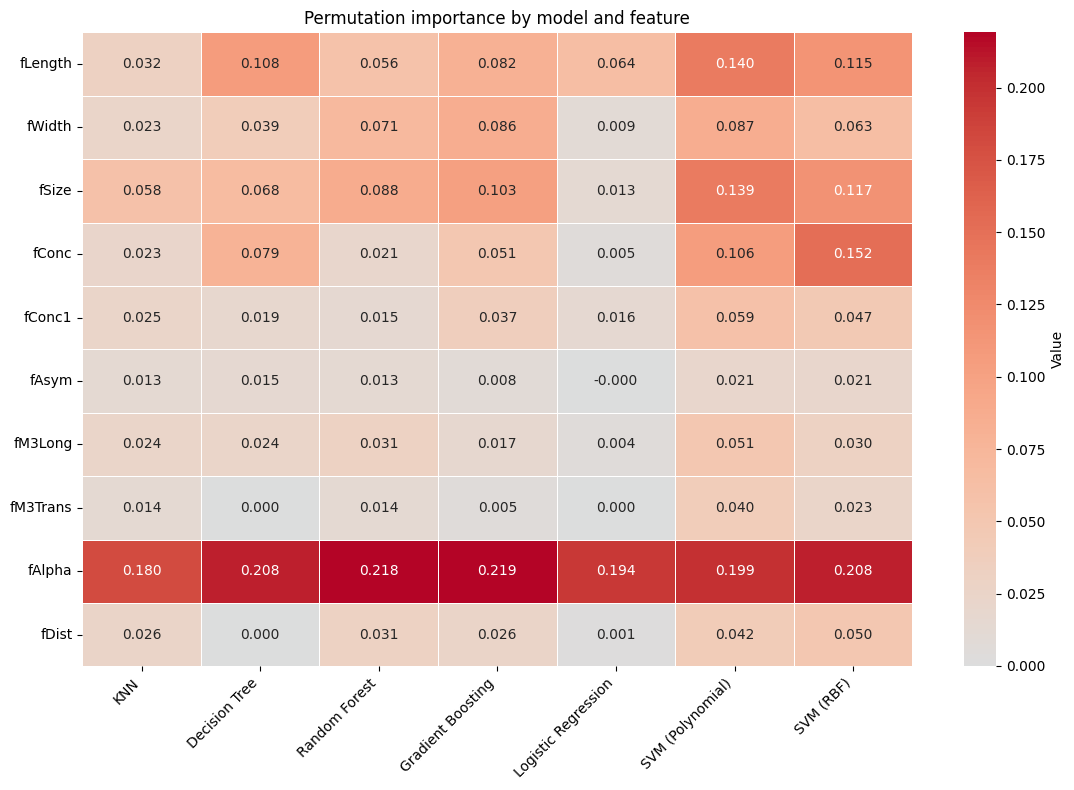

In [ ]:
### YOUR CODE HERE ###

def plot_heatmap(df, title, cmap="coolwarm", center=0, fmt=".3f"):
    """Heatmap of a DataFrame: rows on the y-axis, columns on the x-axis."""
    fig, ax = plt.subplots(figsize=(1.2 * df.shape[1] + 3, 0.6 * df.shape[0] + 2))
    sns.heatmap(
        df,
        annot=True,       
        fmt=fmt,
        cmap=cmap,
        center=center,      
        linewidths=0.5,
        cbar_kws={"label": "Value"},
        ax=ax,
    )
    ax.set_title(title)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

plot_heatmap(importance_df, "Permutation importance by model and feature")

## Part D3: Comparing Models **[4 Marks]**

* Which features are among the top 3 for most models? Which features does almost no model rely on? **[2]**
* Which models disagree the most about which features matter? Give a reason for the disagreement based on how those models make predictions. **[2]**

*Your answer here*

1. Based on the above heatmap, it is evident that the most important features are falpha, flength, and fsize. The least important features appear to be fM3Trans, fAsym, FM3Long, and fDist. 

2. The SVM model with a polynomial kernel disagrees the most with Logistic Regression on the importance of the fsize feature and the fconc feature. This may be due to the fact that logistic regression takes a linear sum of all its features times its weight and computes a probability with the sigmoid function whereas SVM takes the sum of a different function. This difference in their outputs may alter how they consider features due to the shape of the sigmoid function being fundementally different from that of the classification function of the SVM with a polynomial kernel. 

## Part D4: Re-training on the Important Features **[5 Marks]**

Pick one of your 7 models and select its most important features based on your results from Part D1. Explain how you decided which features to keep (e.g. a threshold on the importance, or the top few features). **[1]**

Re-tune the model on the standardized training set using **only the selected features**, with the same hyperparameter search and cross-validation settings you used originally. Report the best mean cross-validation accuracy. **[2]**

How did performance change compared to the same model trained on all 10 features? Why do you think it changed (or didn't)? **[2]**

*Do not use the test set here either.*

In [ ]:
### YOUR CODE HERE ###

# We will choose the SVM model with a polynomial kernel as the model we will examine

# Assume we should keep the top 3 features, we will determine the top 3 features of the model using code: 

N_TOP = 3   # number of top features to return


def top_features(importance_df, model_name, n=N_TOP):
    """Return the n features with the highest mean importance for one model."""
    return importance_df[model_name].nlargest(n)

# Single model
print(top_features(importance_df, "SVM (Polynomial)"))  

X_small_train_scaled_top3 = X_small_train_scaled[top_features(importance_df, "SVM (Polynomial)").index]

# We will now use the same code we used from Part C2.2 with only the top 3 features we have found

RANDOM_STATE = 24  
N_ITER = 250       

# Placeholder: fill in hyperparameter names and distributions
param_dist = {
    "C": expon(scale=10),
    "degree": randint(2, 6),
}

svm_poly_search = RandomizedSearchCV(
    SVC(kernel="poly", random_state=RANDOM_STATE),
    param_distributions=param_dist,
    n_iter=N_ITER,
    cv=5,
    scoring="accuracy",
    verbose=2,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True,
)
svm_poly_search.fit(X_small_train_scaled_top3, y_small_train)

svm_poly_best = svm_poly_search.best_estimator_

print(f"Best mean CV accuracy: {svm_poly_search.best_score_:.4f}")
print("Best hyperparameters:", svm_poly_search.best_params_)

fAlpha     0.198750
fLength    0.139708
fSize      0.138792
Name: SVM (Polynomial), dtype: float64
Fitting 5 folds for each of 250 candidates, totalling 1250 fits
Best mean CV accuracy: 0.7225
Best hyperparameters: {'C': np.float64(21.95742992879343), 'degree': 3}


*Your answer here*

The reported accuracy appears to be 0.7225 which is about 0.0867 less than the original mean accuracy of 0.8092. This may be due to the features that were left out still having an impact on the accuracy of the model and removing them caused that accuracy to be lost. However, it is evident that the top 3 featuers still allowed for the model to maintain the majority of its accuracy. 

# Part E: Evaluation on Test Data **[10 Marks Total]**


## Part E1: Performance measures **[6 Marks]**

Select the model with the highest mean cross-validation accuracy in your Part C3 table (do **not** use the test set to choose), and apply it to the test dataset initially set aside.

Treat gamma rays (`class` = 1) as the positive class. The fall-out rate is the false positive rate: FP / (FP + TN).

Compute the following using the standardized test data (note: never standardize the y data, only standardize the x data):



1.   Accuracy,
2.   Precision,
3.   Recall,
4.   Fall-out rate,
5.   F1 score,
6.   Confusion table

(1 mark for each performance metric)

Accuracy          0.8500
Precision         0.8261
Recall            0.8867
Fall-out (FPR)    0.1867
F1 score          0.8553
dtype: float64


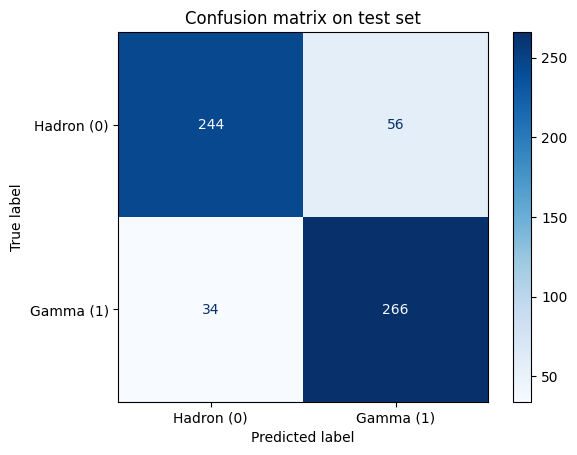

In [ ]:
### YOUR CODE HERE ###

# The model with the highest mean cross validation accuracy is the random forest model. 

best_model = rf_best   # placeholder: your selected tuned model, e.g. rf_best

y_prediction = best_model.predict(X_small_test_scaled)

# labels=[0, 1] fixes the order: rows/cols = [hadron, gamma]
cm = confusion_matrix(y_small_test, y_prediction, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

metrics = pd.Series({
    "Accuracy":       accuracy_score(y_small_test, y_prediction),
    "Precision":      precision_score(y_small_test, y_prediction, pos_label=1),
    "Recall":         recall_score(y_small_test, y_prediction, pos_label=1),
    "Fall-out (FPR)": fp / (fp + tn),
    "F1 score":       f1_score(y_small_test, y_prediction, pos_label=1),
})
print(metrics.round(4))

# Confusion table
ConfusionMatrixDisplay(cm, display_labels=["Hadron (0)", "Gamma (1)"]).plot(cmap="Blues")
plt.title("Confusion matrix on test set")
plt.show()

## Part E2: ROC and AUC **[4 Marks]**

Using the same selected model from the previous part, plot the ROC curve **[2]** and report its AUC **[2]** on the test data.

The ROC curve needs a continuous score for each test sample, not a 0/1 prediction. Use `predict_proba(X_test)[:, 1]` if your model has it; otherwise use `decision_function(X_test)`. For example, `SVC` only has `predict_proba` when created with `probability=True`, but it always has `decision_function`.


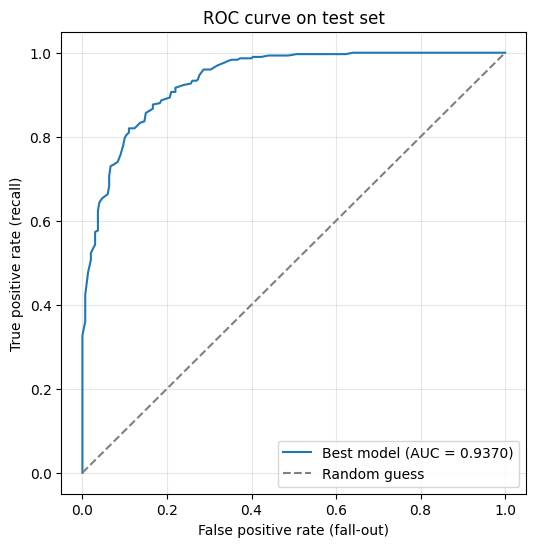

AUC: 0.9370


In [ ]:
### YOUR CODE HERE ###

def plot_roc(model, X, y, label="Model"):
    """Plot the ROC curve for a fitted model and return its AUC."""


    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X)[:, 1]
    else:
        scores = model.decision_function(X)

    fpr, tpr, _ = roc_curve(y, scores, pos_label=1)
    auc = roc_auc_score(y, scores)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.plot(fpr, tpr, label=f"{label} (AUC = {auc:.4f})")
    ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")
    ax.set_xlabel("False positive rate (fall-out)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title("ROC curve on test set")
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)
    plt.show()

    return auc

auc = plot_roc(rf_best, X_small_test_scaled, y_small_test, label="Best model")   
print(f"AUC: {auc:.4f}")


# Bonus: Additional Models **[up to 10 Bonus Marks]**

Pick **up to 2** of the models below. For each model you choose **[5 marks each]**:

1. Tune at least 2 hyperparameters using 5-fold cross-validation on the standardized training set (use `random_state=24` wherever applicable), and report the best mean cross-validation accuracy and hyperparameters. **[2]**
2. Evaluate the best model on the test set using the same metrics as Part E1 and E2 (accuracy, precision, recall, fall-out rate, F1 score, confusion table, and AUC). **[2]**
3. Compare its test performance to your best model from Part E in one or two sentences. **[1]**

| Model | Package | Suggested hyperparameters |
|---|---|---|
| [Shape Generalized Tree (SGT)](https://sgtlearn.readthedocs.io/en/latest/index.html) | `pip install sgtlearn`, then `from sgtlearn import SGTClassifier` | `max_depth`, `min_samples_leaf`, `inner_max_leaf_nodes` |
| [Explainable Boosting Machine (EBM)](https://interpret.ml/docs/ebm.html) | `pip install interpret`, then `from interpret.glassbox import ExplainableBoostingClassifier` | `learning_rate`, `max_leaves`, `interactions` |
| [XGBoost](https://xgboost.readthedocs.io/en/stable/python/sklearn_estimator.html) | `pip install xgboost`, then `from xgboost import XGBClassifier` | `n_estimators`, `max_depth`, `learning_rate` |
| [Fast Interpretable Greedy-Tree Sums (FIGS)](https://csinva.io/imodels/figs.html) | `pip install imodels`, then `from imodels import FIGSClassifier` | `max_rules`, `max_trees`, `min_impurity_decrease` |

*Note: EBMs are slower to fit than the other models (a few seconds per fit), so keep its search small (around 10 candidate settings).*

In [ ]:
### YOUR CODE HERE ###